In [5]:
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from typing import Self
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
# Creating an LLM model
llm1 = HuggingFaceEndpoint(
    repo_id = "meta-llama/Llama-3.1-8B-Instruct",
    task = "text-generation"
)

model = ChatHuggingFace(llm = llm1)

In [12]:
class BlogState(TypedDict):
    topic: str
    outline: str
    blog: str

In [13]:
def get_outline(state: BlogState) -> Self:
    topic = state["topic"]

    prompt = f"Analyse the given topic and generate an outline of it. {topic}"

    result = model.invoke(prompt).content

    state["outline"] = result

    return state

def get_blog(state: BlogState) -> Self:
    topic = state["topic"]
    outline = state["outline"]

    prompt = f"Analyze this topic and outline then generate a Blog on it. Topic: {topic}\nOutline: {outline} "

    blog_result = model.invoke(prompt).content

    state["blog"] = blog_result

    return state

In [14]:
# Create graph
graph = StateGraph(BlogState)

# Add nodes
graph.add_node("get_outline", get_outline)
graph.add_node("get_blog", get_blog)

# Add edges
graph.add_edge(START, "get_outline")
graph.add_edge("get_outline", "get_blog")
graph.add_edge("get_blog", END)

# Compilation
workflow = graph.compile()

In [15]:
# Invocation

initial_state = {"topic": "BTTH"}

result = workflow.invoke(initial_state) 

print(result)

{'topic': 'BTTH', 'outline': "I'd be happy to help with that. However, you haven't specified the topic. Could you please provide the topic you'd like me to analyze and generate an outline for?", 'blog': 'Since you didn\'t specify the topic, I\'ll assume BTTH stands for "Best Things To Hike" or "Bring The Heat" (though I\'m guessing the former is more likely). If not, please let me know what BTTH stands for, and I\'ll assist you accordingly.\n\nAssuming BTTH is related to outdoor activities, I\'ll provide an outline:\n\n**Title:** "Exploring the Best Things To Hike (BTTH): A Guide to Outdoor Adventures"\n\n**I. Introduction**\n\n* Brief overview of the importance of hiking and the benefits it offers\n* Purpose of the blog: to provide a comprehensive guide to the best things to hike (BTTH)\n\n**II. Types of Hiking Trails**\n\n* Overview of different types of hiking trails (e.g., easy, moderate, difficult)\n* Examples of trails in different environments (e.g., forests, mountains, deserts)

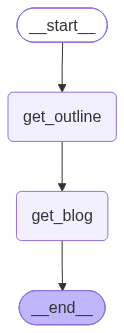

In [11]:
from IPython.display import Image, display 
display(Image(workflow.get_graph().draw_mermaid_png()))